<img src="logo.png" alt="Vegeta" width="240">

# FALCO — the wing and the tail built up in balsa for the laser cutter (36)

FALCO (notebook 35) flies a foam-core wing: an XPS core with a 2 mm balsa D-box on the 20/17 carbon spar, the 12/10 rear
tube and the 16.8/13.5 joiners, and 11 mm foam plates for the stabiliser and the fin. This notebook builds the **same
wing and tail as a rib-and-sheet balsa structure on the same carbon tubes** and cuts every rib on a **10 W diode laser
(xTool D1 Pro class)** with **Atropos**, the new Vegeta tool for flat parts: ribs from the design's own section, the
skin let in where the wing is sheeted, slots for the cap strips, holes for the tubes, lightening holes, the flaps and
ailerons as the ribs' aft pieces split at the hinge line, the kerf, the nesting on 400 x 100 balsa strips, one SVG and
one GRBL G-code file per strip, the cut time and the balsa.

Every build dimension is a stated assumption in `designs/nisus_plus_balsa.BALSA`; the laser settings are an
**illustration** (`vegeta.atropos.examples`): cut a test strip and measure the kerf before trusting them. The planform,
the NACA 3412 section, the tube positions and the hinge lines come from FALCO's design through the `design=` seam.

| part | what | where the code is |
|---|---|---|
| 1 | the cutter, the balsa strips, the operations | `vegeta.atropos.examples` |
| 2 | the rib stations: pitch, forced stations, the tubes, the hinge lines, the thinnest wall | `designs/nisus_plus_balsa.py`, `falco_balsa.py` |
| 3 | the ribs: a gallery, one rib in detail | `vegeta.atropos.rib` |
| 4 | the tail: the stabiliser on its 12/10 spar, the fin on its 10/8 rod | `falco_balsa.tail_parts` |
| 5 | the sheeting blanks and the stock | `sheeting_blanks`, `stock_list` |
| 6 | the cut: nesting, SVG, G-code, time, material | `vegeta.atropos.cut_job` |
| 7 | the mass against the foam wing; the torsion without the foam | `mass_estimate`, `torsion_check` |
| 8 | a rib against the CAD wing's section | `vegeta.dedalus.viz.section_polylines` |
| 9 | the record: `designs/data/falco_balsa_wing.json` | |

In [1]:
# DEBUG: test the notebook end to end before the full run. On here or from the shell:
#   VEGETA_DEBUG=1 jupyter nbconvert --to notebook --execute 36_falco_balsa_wing.ipynb --output 36_falco_balsa_wing-run.ipynb
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys, time
from dataclasses import asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import SVG, display
from vegeta import atropos
from vegeta.dedalus import viz as dviz
from vegeta.atropos import examples as ax
sys.path.insert(0, "designs")
import falco, falco_balsa as fb, falco_structure as fst, falco_systems as fsy, nisus_plus_balsa as nb

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220)
OUT = Path("output") / "36_falco_balsa_wing"; OUT.mkdir(parents=True, exist_ok=True)
for sub in ("sheets", "tables", "plots"):
    (OUT / sub).mkdir(exist_ok=True)
QUICK = os.environ.get("FALCO_QUICK") == "1"
print(f"DEBUG {DEBUG} | QUICK {QUICK}")
def save_table(df, name):
    df.to_csv(OUT / "tables" / f"{name}.csv")
    return df
def show_fig(fig, name):
    fig.savefig(OUT / "plots" / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()
P = falco.resolve()
L = falco.Falco.layout(P)
DES = falco.Falco()

DEBUG False | QUICK False


In [ ]:
from vegeta import yanus
GATE = yanus.enter("36_falco_balsa_wing", debug=DEBUG)              # the door keeper (workflows/flow.py): needs; GateClosed names every fix


# Part 1 — the cutter, the balsa, the operations

An **xTool D1 Pro 10 W**: a 432 x 406 mm bed, GRBL, `S1000` at full power. Balsa comes in 100 x 1000 mm strips; a strip
cut in two and a half gives **400 x 100 mm sheets** that lie on the bed with the grain along X (the ribs' chord). Three
operations: `engrave` (names, not used here), `score` (marks), `cut`. The power, feed, passes and kerf below are
**illustrative values for medium balsa** — the first job on a real machine is a test strip: a 20 mm square per
(power, feed, passes) and a kerf measurement with calipers, into a measured settings module.

In [3]:
SETTINGS = {"balsa": ax.D1_PRO_BALSA_2MM, "ply": ax.D1_PRO_PLY_2MM}
rows = []
for mat, s in SETTINGS.items():
    for op in s.operations.values():
        rows.append({"material": mat, "sheet": s.sheet.name, "thickness [mm]": s.sheet.thickness_mm, "operation": op.name, "power [%]": op.power_pct,
                     "feed [mm/min]": op.feed_mm_min, "passes": op.passes, "kerf [mm]": op.kerf_mm, "source": s.source})
display(save_table(pd.DataFrame(rows).set_index(["material", "operation"]), "laser_settings"))
m = ax.D1_PRO_10W
display(pd.Series({"machine": m.name, "bed [mm]": f"{m.bed_width_mm:g} x {m.bed_height_mm:g}", "rapid feed [mm/min]": m.travel_feed_mm_min, "S at full power": m.s_max,
                   "balsa strip on the bed [mm]": f"{ax.BALSA_400x100_2MM.width_mm:g} x {ax.BALSA_400x100_2MM.height_mm:g} x {ax.BALSA_400x100_2MM.thickness_mm:g}",
                   "margin [mm]": ax.BALSA_400x100_2MM.margin_mm, "part spacing [mm]": ax.D1_PRO_BALSA_2MM.spacing_mm, "balsa density [g/cm³]": ax.BALSA_400x100_2MM.density_g_cm3},
                  name="the cutter").to_frame())
display(pd.DataFrame([{"item": k, "value": v} for k, v in nb.BALSA.items()]).set_index("item").rename(columns={"value": "the build (stated assumptions)"}))

sheet  thickness [mm]  power [%]  feed [mm/min]  passes  kerf [mm]                                                                           source
material operation                                                                                                                                                                                     
balsa    engrave            balsa 400 x 100 x 2 (example)             2.0       12.0         3000.0       1       0.00  illustrative values for a 10 W diode on medium balsa, not measured on a machine
         score              balsa 400 x 100 x 2 (example)             2.0       25.0         1500.0       1       0.00  illustrative values for a 10 W diode on medium balsa, not measured on a machine
         cut                balsa 400 x 100 x 2 (example)             2.0      100.0          600.0       2       0.15  illustrative values for a 10 W diode on medium balsa, not measured on a machine
ply      engrave    birch plywood 400 x 100 x 2 (example)             2.0       12.0         3000.0       1       0.00  illustrative values for a 10 W diode on medium balsa, not measured on a machine
         score      birch plywood 400 x 100 x 2 (example)             2.0       25.0         1500.0       1       0.00  illustrative values for a 10 W diode on medium balsa, not measured on a machine
         cut        birch plywood 400 x 100 x 2 (example)             2.0      100.0          240.0       3       0.15  illustrative values for a 10 W diode on medium balsa, not measured on a machine

,the cutter
machine,xTool D1 Pro 10 W (example)
bed [mm],432 x 406
rapid feed [mm/min],6000.0
S at full power,1000
balsa strip on the bed [mm],400 x 100 x 2
margin [mm],4.0
part spacing [mm],3.0
balsa density [g/cm³],0.16


,the build (stated assumptions)
item,
rib_t,2.0
joint_rib,ply
dbox_t,2.0
sheet_t,1.5
dbox_end,0.03
te_sheet_from,0.85
cap,"(6.0, 2.0)"
cap_fracs,"(0.42, 0.63)"
le_stock,10.0


# Part 2 — the rib stations

Ribs every **60 mm** from the centre strip's edge (|y| = 70 mm, where the taper starts), with ribs **forced** at the
flap's ends (160, 535), **two plywood ribs at the panel joint** (549.5 / 550.5: the centre section's end and the outer
panel's root, where the joiner bears), the aileron's start (567) and the tip; a regular station within 20 mm of a forced
one is dropped. Every rib carries the **main spar** (20/17 to y = 1000, then the 6 mm tip rod) at 30 % chord on the
camber line and, to y = 220, the **rear tube** (12/10) at 55 %. Ribs between the flap's ends are split at 70 % chord,
ribs from the aileron's start at 75 %. The **thinnest wall** around the spar's bore, under the 2 mm D-box sheet let in
on both sides, is the number to watch: 1.1 mm at y = 970 on a 220 mm chord (the foam wing has the same 20 mm tube
under the same 2 mm skins: the design accepted it; a 1.5 mm D-box sheet outboard of the joint would give 1.6 mm).

,y [mm],chord [mm],piece,kind,material,hinge,tubes,spar wall [mm],pieces,area [mm²],cut [mm],holes
rib,,,,,,,,,,,,
W01,70.0,300.00,centre section,root rib,ply,,"spar 20, rear tube 12",5.86,1,5913.85,820.94,5
W02,130.0,294.69,centre section,rib,balsa,,"spar 20, rear tube 12",5.54,1,5692.91,805.73,5
W03,160.0,292.04,centre section,flap end,balsa,0.7,"spar 20, rear tube 12",5.38,2,5422.83,812.55,4
W04,190.0,289.38,centre section,rib,balsa,0.7,"spar 20, rear tube 12",5.22,2,5315.39,805.04,4
W05,250.0,284.07,centre section,rib,balsa,0.7,spar 20,4.90,2,5139.54,769.65,3
W06,310.0,278.76,centre section,rib,balsa,0.7,spar 20,4.58,2,4950.21,753.21,3
W07,370.0,273.45,centre section,rib,balsa,0.7,spar 20,4.26,2,4736.87,733.95,3
W08,430.0,268.14,centre section,rib,balsa,0.7,spar 20,3.95,2,4547.20,717.41,3
W09,490.0,262.83,centre section,rib,balsa,0.7,spar 20,3.63,2,4352.84,702.43,3


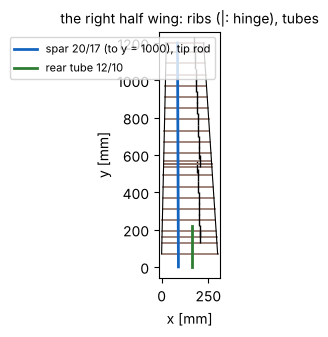

88 rib pieces for both half wings (6 plywood), thinnest spar wall 1.08 mm at y = 970 mm


In [4]:
ST = save_table(fb.station_table(P), "stations")
display(ST.round(2))
fig, ax1 = plt.subplots(figsize=(11, 3.2))
ys = ST["y [mm]"]; cs = ST["chord [mm]"]
x_le = L["le_sweep_tip"] * np.clip((ys - L["yc"]) / (L["b2"] - L["yc"]), 0, 1)
for y, c, xl, hinge in zip(ys, cs, x_le, ST["hinge"]):
    ax1.plot([xl, xl + c], [y, y], color="#8d6e63", lw=1.2)
    if hinge != "":
        ax1.plot([xl + float(hinge) * c], [y], "k|", ms=8)
ax1.plot([0, L["le_sweep_tip"]], [L["yc"], L["b2"]], "k-", lw=0.8); ax1.plot([P["root_chord"], L["le_sweep_tip"] + P["tip_chord"]], [L["yc"], L["b2"]], "k-", lw=0.8)
ax1.plot([P["spar_x_frac"] * P["root_chord"], L["le_sweep_tip"] + P["spar_x_frac"] * P["tip_chord"]], [0, L["b2"]], color="#1565c0", lw=2, label="spar 20/17 (to y = 1000), tip rod")
ax1.plot([P["rear_spar_x_frac"] * P["root_chord"]] * 2, [0, P["rear_spar_half_length"]], color="#2e7d32", lw=2, label="rear tube 12/10")
ax1.set_aspect("equal"); ax1.set_xlabel("x [mm]"); ax1.set_ylabel("y [mm]"); ax1.legend(loc="upper right", fontsize=8); ax1.set_title("the right half wing: ribs (|: hinge), tubes", fontsize=10)
show_fig(fig, "stations")
WING = fb.wing_parts(P)
print(f"{len(WING)} rib pieces for both half wings ({sum(1 for q in WING if q.meta['material'] == 'ply')} plywood), "
      f"thinnest spar wall {ST['spar wall [mm]'].min():.2f} mm at y = {ST.loc[ST['spar wall [mm]'].idxmin(), 'y [mm]']:g} mm")

# Part 3 — the ribs

Every rib from the design's NACA 3412 at the station's chord: the **D-box sheet (2 mm) let in** from the leading edge to
33 % chord on both surfaces, the **trailing-edge sheet (1.5 mm)** from 85 % (a split rib's aft piece — the flap or
aileron rib — is sheeted all over), **cap-strip slots** 6 x 2 at 42 and 63 % in the open bay, the nose cut back 6 mm
for the 10 x 10 leading-edge stock and the tail 12 mm for the 20 x 6 trailing-edge stock, the **tube holes with 0.3 mm
glue clearance**, **lightening holes** (≤ 40 mm, a 5 mm wall) where they fit, and the **hinge split** with a 1.5 mm gap
and a 12° wedge on the control surface's nose.

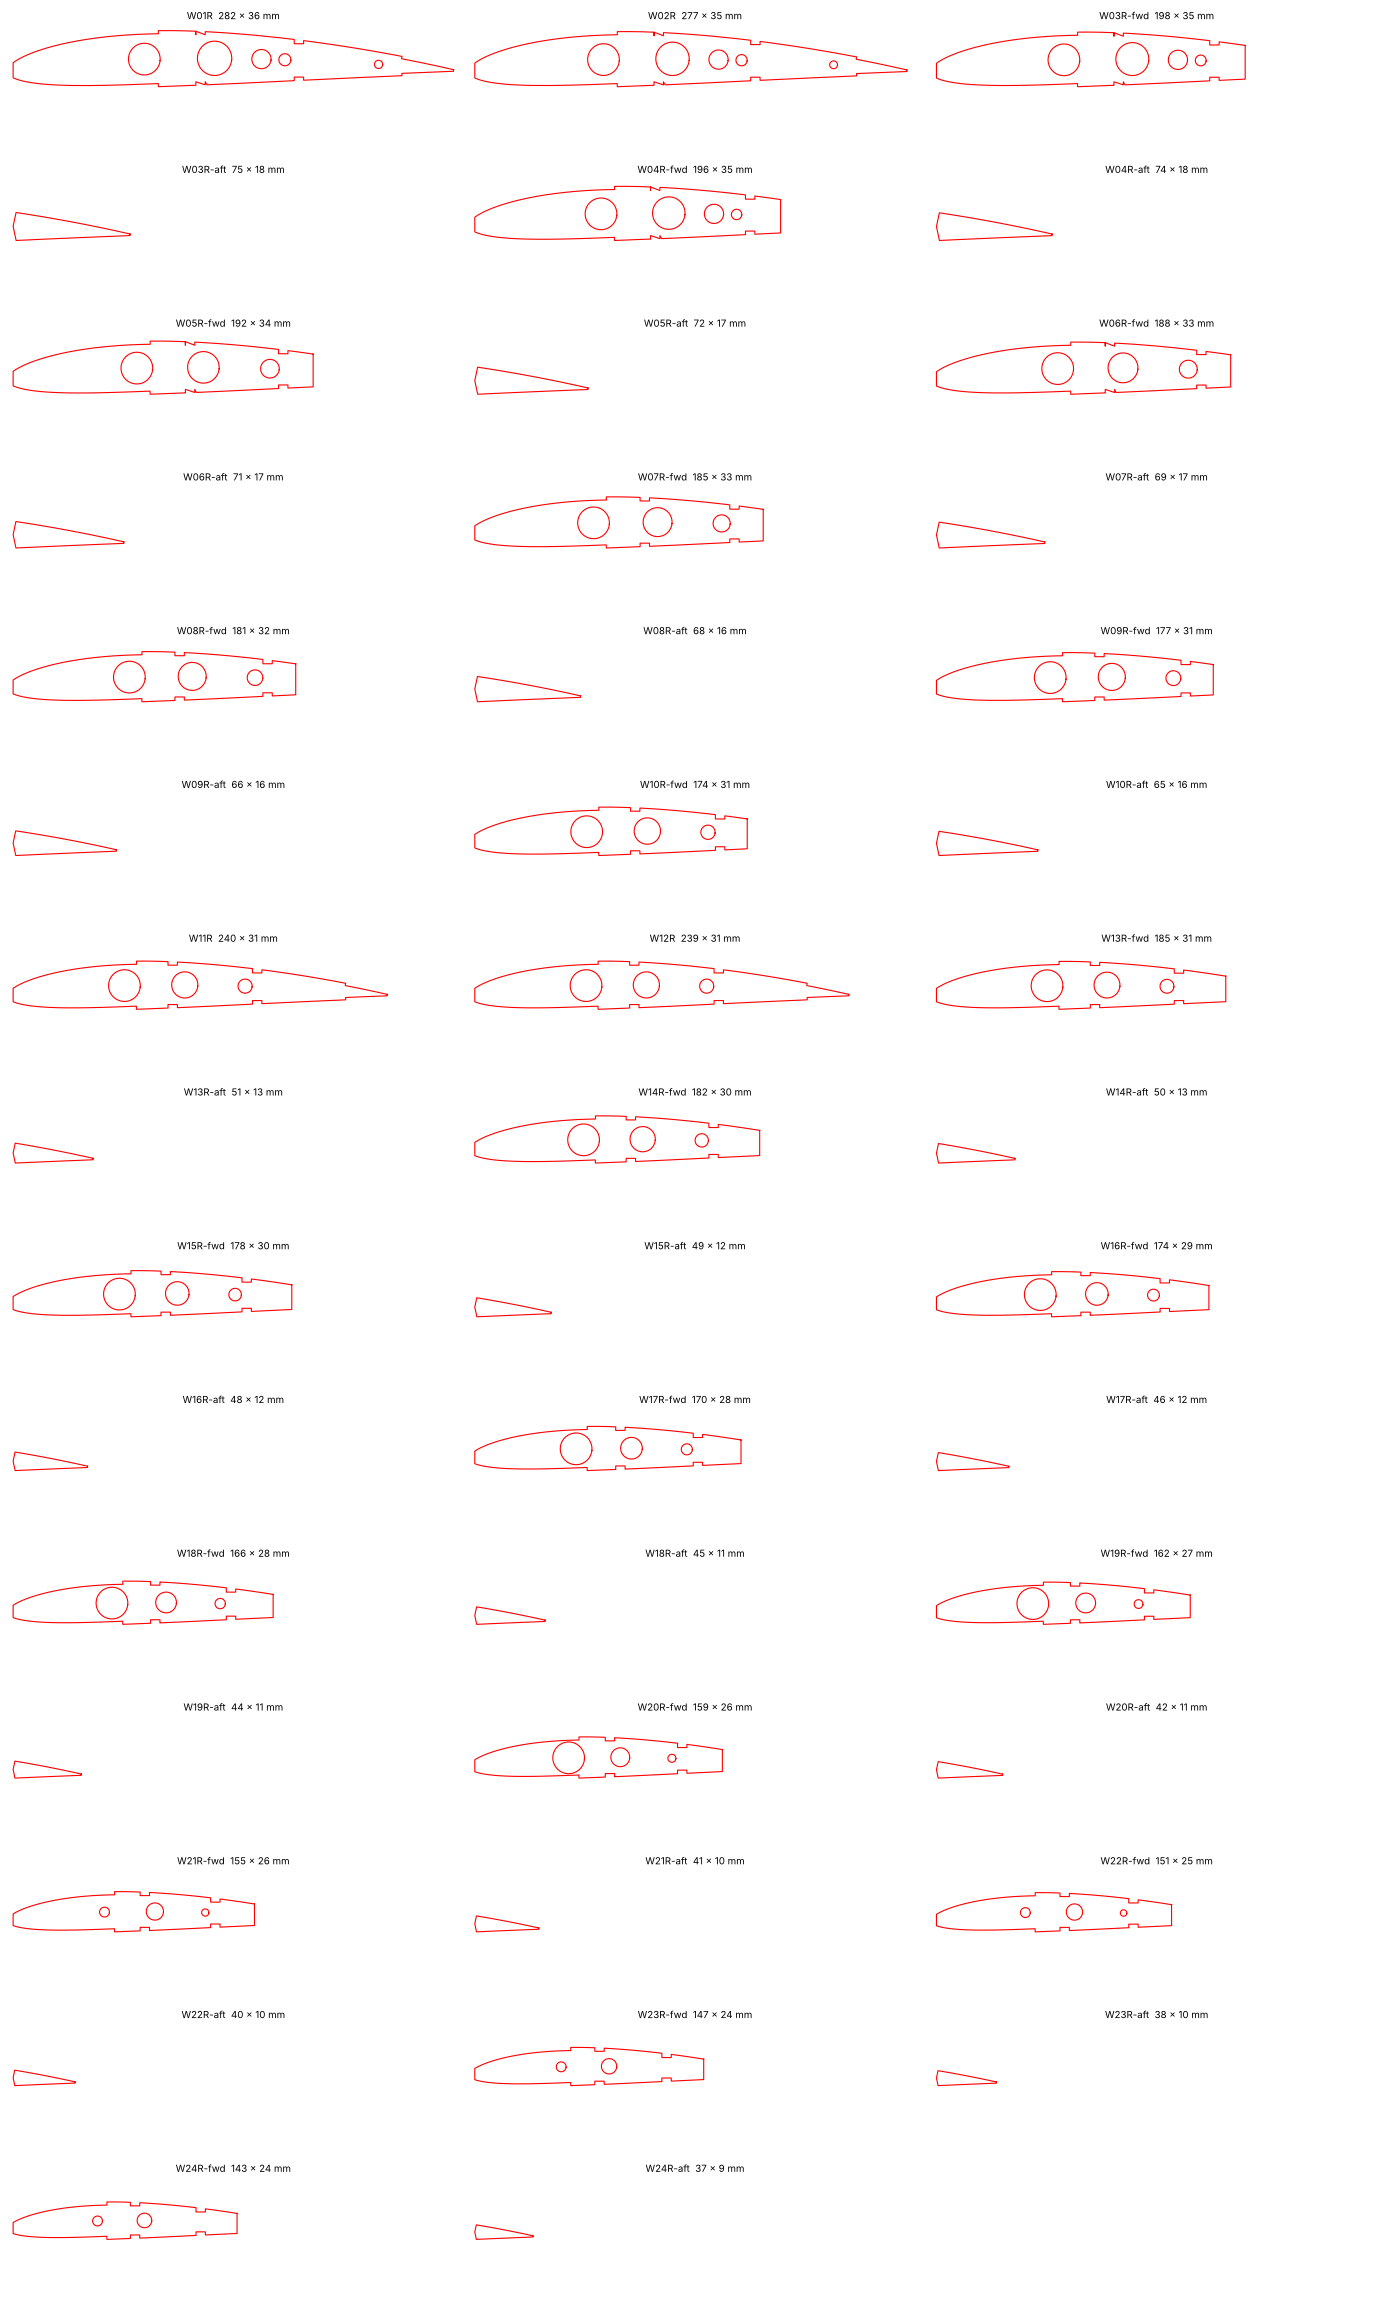

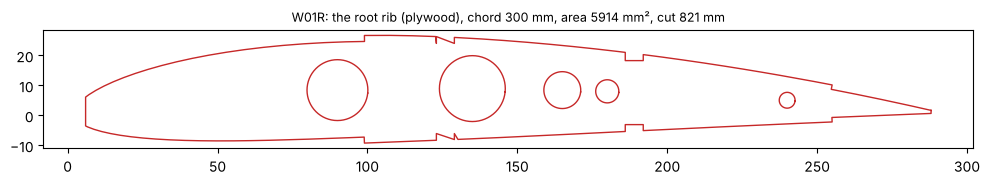

,y [mm],width [mm],height [mm],area [mm²],cut [mm],holes
count,88.0,88.0,88.0,88.0,88.0,88.0
mean,634.1,127.2,22.5,2253.4,361.8,1.7
std,327.6,72.4,9.1,1810.9,235.6,1.7
min,70.0,37.3,9.3,192.0,83.5,0.0
25%,370.0,51.0,12.7,357.2,114.2,0.0
50%,588.6,148.6,24.8,2676.5,399.5,2.5
75%,910.0,181.3,30.8,3781.9,557.4,3.0
max,1198.0,282.0,35.9,5913.8,820.9,5.0


In [5]:
right = [q for q in WING if q.meta["side"] == "R"]
show_fig(atropos.plot_parts(right, ncols=3, width_in=14), "rib_gallery")
root = next(q for q in WING if q.name == "W01R")
fig, ax2 = plt.subplots(figsize=(12, 2.4))
for q in (root,):
    for p_ in q.paths():
        pts = np.vstack([p_.points, p_.points[:1]])
        ax2.plot(pts[:, 0], pts[:, 1], color="#c62828", lw=1)
ax2.set_aspect("equal"); ax2.set_title(f"{root.name}: the root rib (plywood), chord {root.meta['chord_mm']:g} mm, area {root.area():.0f} mm², cut {root.cut_length():.0f} mm", fontsize=9)
show_fig(fig, "root_rib")
PARTS = save_table(pd.DataFrame([{"part": q.name, "y [mm]": q.meta["station_y"], "piece": q.meta["piece"], "role": q.meta["role"], "material": q.meta["material"],
                                  "width [mm]": q.size()[0], "height [mm]": q.size()[1], "area [mm²]": q.area(), "cut [mm]": q.cut_length(), "holes": len(q.holes)}
                                 for q in WING]).set_index("part"), "wing_parts")
display(PARTS.describe().round(1))

# Part 4 — the tail

The stabiliser (560 x 190) and the fin (360 high, 270 chord) as ribs every 40 mm on the **12/10 spar at 30 % chord**
and the **10/8 rod at 45 % of the fin's chord** (300 mm up from the root), split at the elevator (65 %) and the rudder
(65 %). One deviation from the foam tail is **stated in `BALSA`**: the built-up tail is a **NACA 0010**, not the 0006 of
the foam plates — a 12.3 mm bore does not fit an 11.4 mm thick section with the sheeting let in. The tail's area and
arm are unchanged; the thicker section is a few grams of drag the foam plate's square edges spent anyway.

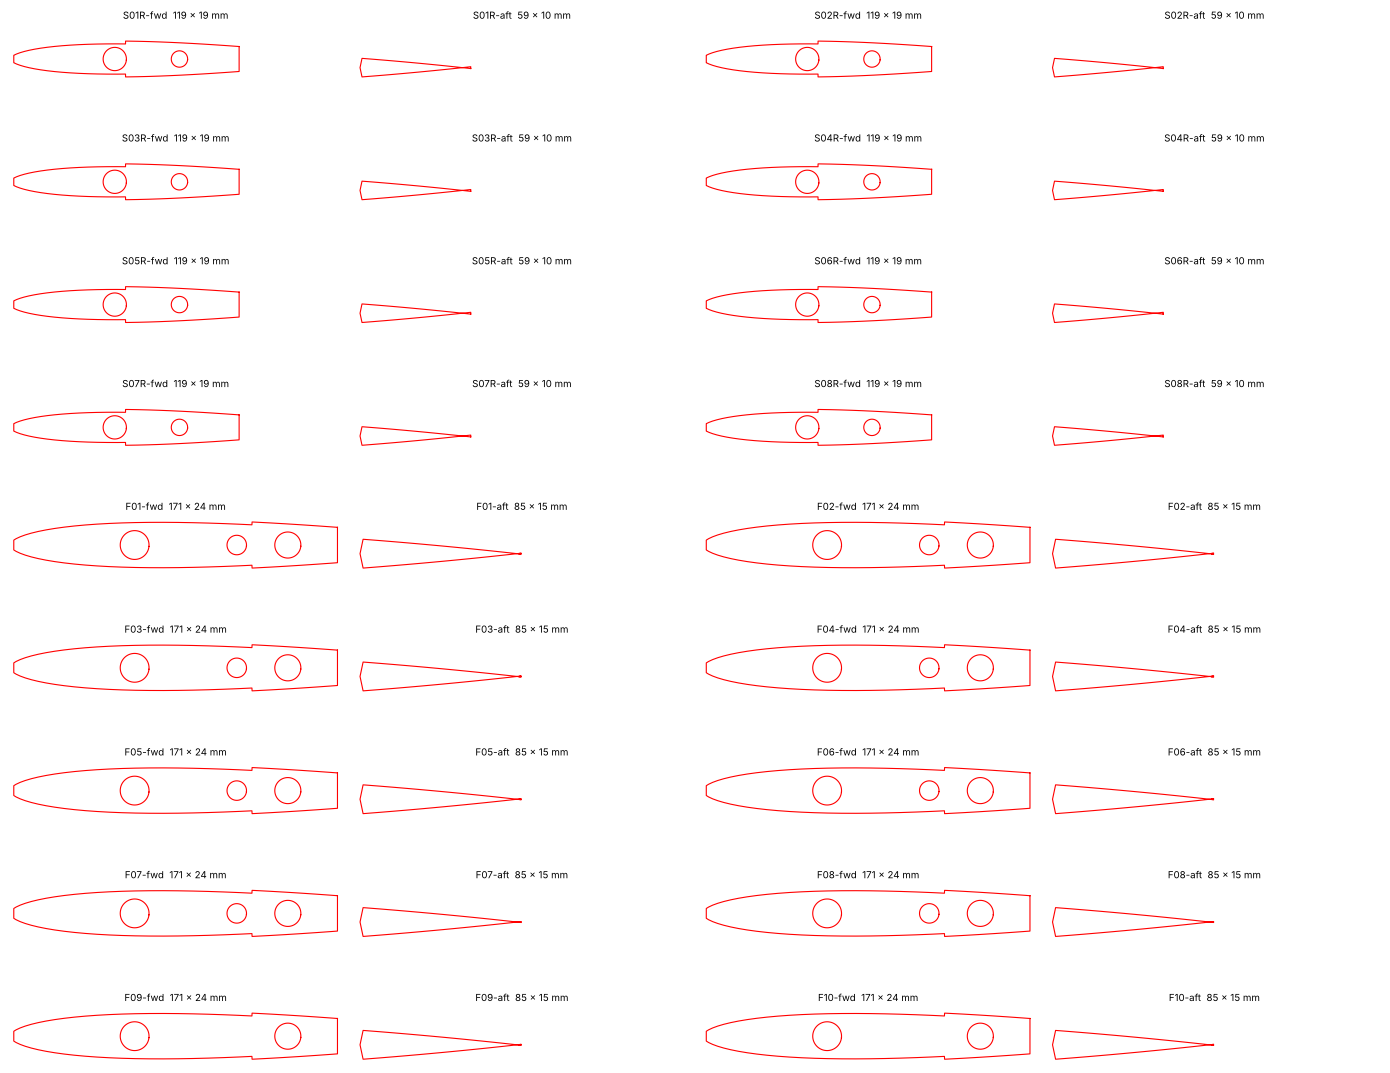

52 tail rib pieces: 32 stabiliser, 20 fin


In [6]:
TAIL = fb.tail_parts(P)
show_fig(atropos.plot_parts([q for q in TAIL if q.meta.get("side", "") != "L"], ncols=4, width_in=14), "tail_gallery")
print(f"{len(TAIL)} tail rib pieces: {sum(1 for q in TAIL if q.meta['surface'] == 'stabiliser')} stabiliser, {sum(1 for q in TAIL if q.meta['surface'] == 'fin')} fin")

# Part 5 — the sheeting blanks and the stock

What the ribs do not say: the **sheeting** as flat blanks (the D-box upper and lower from the leading edge to 33 %, the
trailing-edge sheet from 85 %; a trapezoid per wing piece whose widths are the section's arc lengths at its ends), and
the **stock** — leading- and trailing-edge strips, cap strips, the shear web behind the spar. These are sawn and planed
from strips, not laser-cut (a 200 mm wide D-box blank does not fit a 100 mm strip; it is two sheets anyway).

In [7]:
SHEETS = save_table(fb.sheeting_blanks(P), "sheeting_blanks")
display(SHEETS.round(1))
STOCK = save_table(fb.stock_list(P), "stock")
display(STOCK.round(1))

,piece,sheet,surface,y0 [mm],y1 [mm],length [mm],width root [mm],width tip [mm],thickness [mm],area [cm²],mass [g],count
0,centre section,D-box,upper,70.0,550.0,480.7,107.9,92.6,2.0,482.0,30.9,2
1,centre section,trailing edge,upper,70.0,550.0,480.7,45.8,39.3,1.5,204.6,9.8,2
2,centre section,D-box,lower,70.0,550.0,480.7,102.1,87.7,2.0,456.2,29.2,2
3,centre section,trailing edge,lower,70.0,550.0,480.7,45.0,38.7,1.5,201.1,9.7,2
4,outer panel,D-box,upper,550.0,1200.0,650.9,92.6,72.0,2.0,535.7,34.3,2
5,outer panel,trailing edge,upper,550.0,1200.0,650.9,39.3,30.5,1.5,227.4,10.9,2
6,outer panel,D-box,lower,550.0,1200.0,650.9,87.7,68.1,2.0,507.0,32.4,2
7,outer panel,trailing edge,lower,550.0,1200.0,650.9,38.7,30.0,1.5,223.5,10.7,2
8,centre strip,"D-box + TE, both surfaces",both,-70.0,70.0,140.0,NaN,NaN,2.0,421.3,12.5,1


,piece,item,length [mm],count,section [mm²],mass [g]
0,centre strip,LE stock 10 x 10 triangle,140.0,1,50.0,1.1
1,centre strip,TE stock 20 x 6 tapered,140.0,1,60.0,1.3
2,centre section,LE stock 10 x 10 triangle,480.7,2,50.0,7.7
3,centre section,TE stock 20 x 6 tapered,480.7,2,60.0,9.2
4,centre section,cap strips 6 x 2,480.7,8,12.0,7.4
5,centre section,"shear web behind the spar, 2 mm, grain vertical",480.7,2,53.5,8.2
6,outer panel,LE stock 10 x 10 triangle,650.9,2,50.0,10.4
7,outer panel,TE stock 20 x 6 tapered,650.9,2,60.0,12.5
8,outer panel,cap strips 6 x 2,650.9,8,12.0,10.0
9,outer panel,"shear web behind the spar, 2 mm, grain vertical",650.9,2,43.9,9.1


# Part 6 — the cut

Two jobs: the balsa ribs (2 mm, both wings and the tail) and the six plywood ribs (2 mm). Atropos moves every outer
contour out by half the kerf and every hole in, nests the pieces on 400 x 100 strips (tallest first, long side along
the grain, 3 mm apart, 4 mm margins) and writes **one SVG and one G-code file per strip** into `output/36_.../sheets/`
with a preview. The time is path length over feed (two passes at 600 mm/min for 2 mm balsa, three at 240 for the
ply) plus the rapids: the real machine adds its accelerations.

In [8]:
t0 = time.time()
RES = fb.cut_plan(WING + TAIL, SETTINGS, OUT / "sheets", name="falco")
CUT = save_table(fb.cut_summary(RES), "cut_summary")
display(CUT.round(2))
for mat, r in RES.items():
    print(f"{mat}: {r.status}, {r.metrics['sheets']} sheets, {r.metrics['time_s'] / 60:.0f} min; files in {Path(r.artifacts['svg_01']).parent}")
print(f"{time.time() - t0:.1f} s")

,status,parts,sheets,cut length [m],travel [m],time [min],utilisation,parts mass [g],sheets mass [g]
material,,,,,,,,,
balsa,success,134,15,82.99,20.50,141.74,0.40,76.23,192.0
ply,success,6,3,12.85,2.69,54.00,0.25,39.57,163.2


balsa: success, 15 sheets, 142 min; files in output/36_falco_balsa_wing/sheets/balsa
ply: success, 3 sheets, 54 min; files in output/36_falco_balsa_wing/sheets/ply
4.5 s


sheet 1 of the balsa job as the cutter software sees it (red: cut):


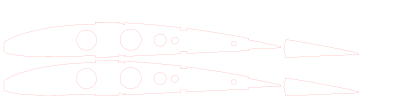

['; falco balsa sheet 1/15', '; machine: xTool D1 Pro 10 W (example); sheet: balsa 400 x 100 x 2 (example)', '; operations: cut 100 % 600 mm/min x 2', 'G21 G90 G17', 'M5', 'G0 F6000', '; --- cut: S1000 F600 passes 2 kerf 0.15 mm', 'M4 S1000', '; part W02L', 'G0 X96.508 Y20.448', 'G1 X96.363 Y19.470 F600 S1000', 'G1 X96.123 Y18.511']


In [9]:
show_fig(atropos.plot_nesting(RES["balsa"].nesting, SETTINGS["balsa"].operations, labels=True, max_sheets=3), "sheets_balsa")
show_fig(atropos.plot_nesting(RES["ply"].nesting, SETTINGS["ply"].operations, labels=True), "sheets_ply")
print("sheet 1 of the balsa job as the cutter software sees it (red: cut):")
display(SVG(filename=str(RES["balsa"].artifacts["svg_01"])))
print(Path(RES["balsa"].artifacts["gcode_01"]).read_text().splitlines()[:12])

# Part 7 — the mass against the foam wing; the torsion without the foam

The balsa estimate counts the ribs from their cut areas, the sheeting blanks, the stock and 10 % glue; the foam wing's
rows it replaces are FALCO's mass table's XPS core, its D-box line and the foam tail plates. The torsion check is
NISUS+'s D-box check at V_NE with the foam's share set to zero: the 2 mm D-box and the spar tube carry the torque.

In [10]:
MASS = save_table(fb.mass_estimate(P, wing=WING, tail=TAIL), "mass_estimate")
display(MASS.round(1))
CMP = save_table(fb.mass_comparison(P, MASS), "mass_comparison")
display(CMP.round(1))
print(f"foam wing and tail {CMP.attrs['foam_g']:.0f} g, built-up {CMP.attrs['balsa_g']:.0f} g: {CMP.attrs['delta_g']:+.0f} g")
CASES = fst.load_cases(P)
TORS = save_table(fb.torsion_check(P, CASES), "torsion")
display(TORS)

,count,mass [g]
item,,
wing ribs (balsa 2 mm),82,54.1
wing ribs (ply 2 mm),6,39.6
tail ribs (balsa 2 mm),52,22.1
"wing sheeting (D-box 2 mm, trailing edge 1.5 mm)",17,180.4
wing LE stock 10 x 10 triangle,5,19.2
wing TE stock 20 x 6 tapered,5,23.1
wing cap strips 6 x 2,16,17.4
wing shear web behind the spar,4,17.4
tail sheeting 1.5 mm and stock,1,76.2


,mass [g],wing
item,,
wing: XPS core (25 % lightened),287.6,foam wing
"wing: balsa D-box 2 mm (LE to spar, full span), TE strips, servo bays, joint ribs",146.0,foam wing
tail: foam stabiliser and fin (11 mm plates),57.0,foam wing
"built-up wing and tail (balsa, ply, glue)",494.4,balsa wing


foam wing and tail 491 g, built-up 494 g: +4 g


,value
check,
"torque per wing at V_NE, ultimate [N m]",11.119631
"torsional stiffness shares (D-box / spar), no foam",0.45 / 0.55
"balsa D-box shear, 2 mm sheet [MPa]",0.505035
balsa D-box margin (shear 1.5 MPa assumed x 0.7),1.079063
spar tube torsion shear [MPa],8.097407
spar torsion margin (in-plane shear 40 MPa x 0.8),2.951882
"wing tip twist at V_NE, limit [deg]",3.711578
the foam wing's twist by the same formula [deg],3.12302
twist verdict,1.19 x the foam wing's twist: stiffen the D-box (sheet thicker or further aft)


# Part 8 — a rib against the CAD wing's section

The ribs are drawn from the section formula at the station's chord; the CAD wing is a ruled loft between the root and
the tip sections. One check that both agree: the CAD wing sliced at a station (`dedalus.viz.section_polylines`), the
incidence and the dihedral undone, against the plain section outline the rib starts from.

In [11]:
if DEBUG or QUICK:
    print("NOT RUN (DEBUG/QUICK)")
    CAD_CHECK = None
else:
    from fixed_wing import naca4
    t0 = time.time()
    wing_geo = DES.generate(part="wing")
    a = math.radians(P["wing_incidence_deg"]); xq = 0.25 * P["root_chord"]
    up, lo = naca4(P["camber"], P["camber_pos"], P["thickness"], n=60)
    rows = []
    for st in (fb.rib_stations(P)[1], fb.rib_stations(P)[12], fb.rib_stations(P)[-1]):
        y = st["y"]
        polys = dviz.section_polylines(wing_geo, "y", y, tolerance=0.02)
        pts = np.vstack(polys)
        X, Z = pts[:, 0], pts[:, 1]
        x_ = xq + (X - xq) * math.cos(a) - Z * math.sin(a)
        z_ = (X - xq) * math.sin(a) + Z * math.cos(a)
        f_span = max(0.0, (y - L["yc"]) / (L["b2"] - L["yc"]))
        local = np.stack([x_ - L["le_sweep_tip"] * f_span, z_ - max(0.0, y - L["yc"]) * math.tan(math.radians(P["dihedral_deg"]))], axis=1)
        outline = atropos.Path(atropos.section_outline(up, lo, st["chord"]))
        d = np.array([outline.distance(x, z) for x, z in local])
        rows.append({"y [mm]": y, "chord [mm]": st["chord"], "CAD section points": len(local), "max distance to the rib's section [mm]": d.max(), "mean [mm]": d.mean()})
    CAD_CHECK = save_table(pd.DataFrame(rows).set_index("y [mm]"), "cad_check")
    display(CAD_CHECK.round(3))
    print(f"{time.time() - t0:.0f} s; the ruled loft between two NACA sections and the section at the station's chord agree to {CAD_CHECK.iloc[:, 2].max():.2f} mm")

,chord [mm],CAD section points,max distance to the rib's section [mm],mean [mm]
y [mm],,,,
130.0,294.690,95,0.172,0.023
567.2,256.000,95,0.960,0.048
1198.0,200.177,95,0.031,0.013


4 s; the ruled loft between two NACA sections and the section at the station's chord agree to 0.96 mm


# Part 9 — the record and the verdict

In [12]:
def plain(x):
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x
RECORD = {"source": "36_falco_balsa_wing", "build": {k: plain(v) if not isinstance(v, (dict, tuple)) else v for k, v in nb.BALSA.items()},
          "laser_settings": {k: s.to_dict() for k, s in SETTINGS.items()},
          "stations": {k: {kk: plain(vv) for kk, vv in row.items()} for k, row in ST.T.to_dict().items()},
          "parts": {"wing": len(WING), "tail": len(TAIL), "ply": sum(1 for q in WING if q.meta["material"] == "ply")},
          "cut": {k: {kk: plain(vv) for kk, vv in row.items()} for k, row in CUT.T.to_dict().items()},
          "mass": {k: {kk: plain(vv) for kk, vv in row.items()} for k, row in MASS.T.to_dict().items()},
          "mass_comparison": {"foam_g": plain(CMP.attrs["foam_g"]), "balsa_g": plain(CMP.attrs["balsa_g"]), "delta_g": plain(CMP.attrs["delta_g"])},
          "torsion": {k: plain(v) for k, v in TORS.attrs.items()},
          "cad_check": None if CAD_CHECK is None else {str(k): {kk: plain(vv) for kk, vv in row.items()} for k, row in CAD_CHECK.T.to_dict().items()}}
Path("designs/data/falco_balsa_wing.json").write_text(json.dumps(RECORD, indent=1))
tw, tf = TORS.attrs["twist_deg"], TORS.attrs["twist_foam_deg"]
print(f"ribs: {len(WING)} wing pieces + {len(TAIL)} tail pieces on {int(CUT['sheets'].sum())} strips, {CUT['time [min]'].sum():.0f} min of cutting")
print(f"mass: built-up {CMP.attrs['balsa_g']:.0f} g against the foam wing and tail's {CMP.attrs['foam_g']:.0f} g ({CMP.attrs['delta_g']:+.0f} g)")
print(f"torsion at V_NE: {tw:.1f} deg of tip twist against the foam wing's {tf:.1f} deg ({tw / tf:.2f} x); D-box shear margin "
      f"{float(TORS.loc['balsa D-box margin (shear 1.5 MPa assumed x 0.7)', 'value']):.2f}")

ribs: 88 wing pieces + 52 tail pieces on 18 strips, 196 min of cutting
mass: built-up 494 g against the foam wing and tail's 491 g (+4 g)
torsion at V_NE: 3.7 deg of tip twist against the foam wing's 3.1 deg (1.19 x); D-box shear margin 1.08


**Verdict.** The built-up wing is cut from the design's own numbers: every rib fits its 100 mm strip, the spar's bore
keeps 1.1 mm of rib under the D-box sheet (as the foam wing does), the control surfaces come out as the ribs' aft pieces. It weighs
about what the foam wing weighs (the foam wing was already a D-box wing; the balsa sheeting is most of the mass) and
twists a little more at V_NE without the foam's share — the D-box sheet a size thicker or carried further aft would
close that. Before the first real cut: the test strip (the kerf, the passes), then one rib and its tube for the
0.3 mm glue fit (`todo.md`, 5q.3).

In [ ]:
STAMPS = GATE.leave()          # the files this notebook gives (workflows/flow.py) written by this run, stamped for the notebooks that read them
